# Figure 3

In this notebook, we'll generate figure panels for use in Figure 2, the overview of Bortezomib treatment results.

For the UMAP plots, see the notebook for Figure 1. In this notebook, we'll generate the differential result barplots, Hallmark Pathway heatmaps, and motif enrichment volcano plots.

## Load packages

hise: The Human Immune System Explorer R SDK package  
purrr: Functional programming tools  
dplyr: Dataframe handling functions  
ggplot2: plotting functions  
ggrepel: text plotting with repulsion  
cowplot: multi-panel plot assembly

In [1]:
quiet_library <- function(...) { suppressPackageStartupMessages(library(...)) }
quiet_library(hise)
quiet_library(purrr)
quiet_library(dplyr)
quiet_library(ggplot2)
quiet_library(ggrepel)
quiet_library(cowplot)

Warning message:
“package ‘purrr’ was built under R version 4.4.3”
Warning message:
“package ‘dplyr’ was built under R version 4.4.3”
Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘ggrepel’ was built under R version 4.4.3”
Warning message:
“package ‘cowplot’ was built under R version 4.4.3”


In [2]:
out_dir <- "output/figure_3"
if(!dir.exists(out_dir)) { dir.create(out_dir, recursive = TRUE) }

## Retrieve files

Now, we'll use the HISE SDK package to retrieve the analysis results for DEG, Hallmark Pathway enrichment, and motif enrichment.

DEG: Differentially expressed genes

In [3]:
deg_uuid <- list("fc83b89f-fd26-43b8-ac91-29c539703a45")

In [4]:
deg_file <- cacheFiles(deg_uuid)

[2026-11-06 14:32:24] INFO  Calling cacheFiles
[1] "downloading fileID fc83b89f-fd26-43b8-ac91-29c539703a45"
[2026-11-06 14:32:29] INFO  Finished cacheFiles successfully (time_elapsed=2.867s)


DEP: Differentially expressed proteins (ADT)

In [5]:
dep_uuid <- list("4cbaa9ab-f8ef-495d-ac5e-1f1d99d33e33")

In [6]:
dep_file <- cacheFiles(dep_uuid)

[2026-11-06 14:32:29] INFO  Calling cacheFiles
[1] "downloading fileID 4cbaa9ab-f8ef-495d-ac5e-1f1d99d33e33"
[2026-11-06 14:32:34] INFO  Finished cacheFiles successfully (time_elapsed=1.926s)


DAP: Differentially accessible peaks (ATAC)

In [7]:
dap_uuid <- list("a8973524-cc71-40d5-8edf-3d6a9e0a77d4")

In [8]:
dap_file <- cacheFiles(dap_uuid)

[2026-11-06 14:32:34] INFO  Calling cacheFiles
[1] "downloading fileID a8973524-cc71-40d5-8edf-3d6a9e0a77d4"
[2026-11-06 14:32:38] INFO  Finished cacheFiles successfully (time_elapsed=1.957s)


In [9]:
hallmark_uuid <- list("4f05f2a0-59d2-4d04-b948-70d541613e71")

In [10]:
hallmark_file <- cacheFiles(hallmark_uuid)

[2026-11-06 14:32:38] INFO  Calling cacheFiles
[1] "downloading fileID 4f05f2a0-59d2-4d04-b948-70d541613e71"
[2026-11-06 14:32:44] INFO  Finished cacheFiles successfully (time_elapsed=1.976s)


In [11]:
dem_uuid <- list("42adb44f-71d2-4d8b-a80c-73b0833d6a1d")

In [12]:
dem_file <- cacheFiles(dem_uuid)

[2026-11-06 14:32:44] INFO  Calling cacheFiles
[1] "downloading fileID 42adb44f-71d2-4d8b-a80c-73b0833d6a1d"
[2026-11-06 14:32:49] INFO  Finished cacheFiles successfully (time_elapsed=1.893s)


## Differential expression barplots

### DEG Barplots

In [13]:
fdr_cutoff <- 0.05

In [14]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv")

In [15]:
all_deg <- read.csv(deg_file)

In [16]:
all_deg <- all_deg %>%
  mutate(
      direction_sign = ifelse(
          is.na(logFC),
          sign(coef_D),
          sign(logFC)
      ),
      direction = ifelse(
          direction_sign == 1,
          "up", "dn"
      )
  )

In [17]:
all_deg <- all_deg %>%
  filter(fg == "bortezomib")

In [18]:
deg_summary <- all_deg %>%
  group_by(fg, timepoint, aifi_cell_type, n_sample) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [19]:
plot_data <- deg_summary %>%
  rename(aifi_cell_type = aifi_cell_type) %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [20]:
plot_data %>%
  filter(fg == "bortezomib",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sample,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<int>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
bortezomib,4,t_cd4_naive,1352,0,0,0,CD4 Naive,#93A7D1,1,7,bortezomib_4,3755
bortezomib,24,t_cd4_naive,1352,451,264,187,CD4 Naive,#93A7D1,1,7,bortezomib_24,3755
bortezomib,72,t_cd4_naive,1352,6832,3755,3077,CD4 Naive,#93A7D1,1,7,bortezomib_72,3755


In [21]:
write.csv(
    plot_data,
    file.path(out_dir, paste0("bortezomib_deg_summary_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [22]:
treat_times <- paste0("bortezomib_", c(4, 24, 72))

In [23]:
options(repr.plot.width = 12, repr.plot.height = 4)
treat_plots <- map(
    treat_times,
    function(tt) {
                
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        
        timepoint <- pd$timepoint[1]
        pd_max <- max(max(pd$n_dn), max(pd$n_up))
        if(pd_max < 100) {
            pd_max <- 100
        }
        
        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sample, n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.2, y = cell_type_ypos,
                        label = n_sample),
                    hjust = 1)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DEGs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

In [24]:
treat_times

[1] "bortezomib_4"  "bortezomib_24" "bortezomib_72"

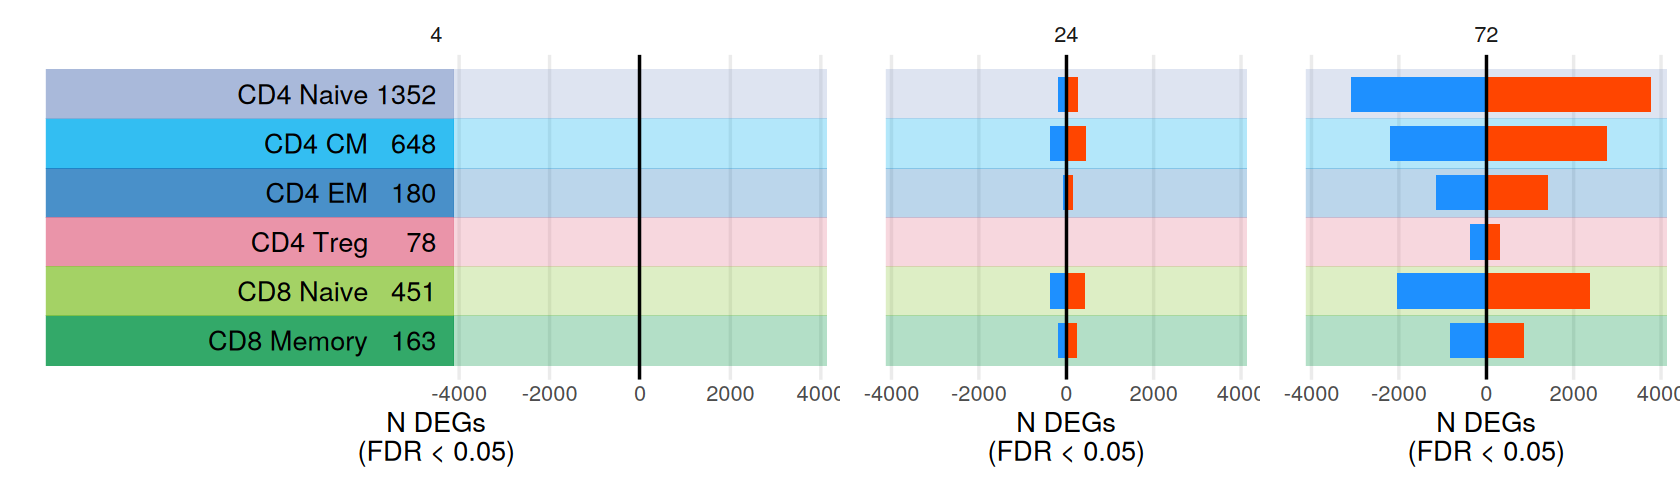

In [25]:
options(repr.plot.width = 14, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 3,
    rel_widths = c(2,1,1)
)
all_plots

In [26]:
out_file <- file.path(
    out_dir,
    paste0("bortezomib_deg_barplot_",Sys.Date(),".pdf")
)
ggsave(out_file,
       all_plots,
       width = 14, height = 4)

### DAP Barplots

In [27]:
fdr_cutoff <- 0.05

In [28]:
all_dap <- read.csv(dap_file)

In [29]:
head(all_dap)

,aifi_cell_type,fg,bg,seqnames,start,end,logFC,adjP,MeanDiff,idx
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>
1,t_cd4_cm,bortezomib_4,dmso_4,chr1,817097,817597,0.76247158,0.9617006,0.016549055,1
2,t_cd4_cm,bortezomib_4,dmso_4,chr1,827316,827816,-0.01214597,0.9617006,-0.002062272,2
3,t_cd4_cm,bortezomib_4,dmso_4,chr1,844402,844902,-0.72051897,0.9617006,-0.017751078,3
4,t_cd4_cm,bortezomib_4,dmso_4,chr1,903980,904480,-1.17605733,0.9617006,-0.016888331,6
5,t_cd4_cm,bortezomib_4,dmso_4,chr1,904495,904995,-0.21563641,0.9617006,-0.040113108,7
6,t_cd4_cm,bortezomib_4,dmso_4,chr1,942207,942707,-0.89654326,0.9617006,-0.042661663,16


In [30]:
all_dap <- all_dap %>%
  mutate(timepoint = sub(".+_","",fg),
         fg = sub("_.+","",fg),
         bg = sub("_.+","",bg)) %>%
  filter(fg == "bortezomib") %>%
  mutate(direction = ifelse(logFC > 0, "up", "dn"))

In [31]:
head(all_dap)

,aifi_cell_type,fg,bg,seqnames,start,end,logFC,adjP,MeanDiff,idx,timepoint,direction
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<chr>,<chr>
1,t_cd4_cm,bortezomib,dmso,chr1,817097,817597,0.76247158,0.9617006,0.016549055,1,4,up
2,t_cd4_cm,bortezomib,dmso,chr1,827316,827816,-0.01214597,0.9617006,-0.002062272,2,4,dn
3,t_cd4_cm,bortezomib,dmso,chr1,844402,844902,-0.72051897,0.9617006,-0.017751078,3,4,dn
4,t_cd4_cm,bortezomib,dmso,chr1,903980,904480,-1.17605733,0.9617006,-0.016888331,6,4,dn
5,t_cd4_cm,bortezomib,dmso,chr1,904495,904995,-0.21563641,0.9617006,-0.040113108,7,4,dn
6,t_cd4_cm,bortezomib,dmso,chr1,942207,942707,-0.89654326,0.9617006,-0.042661663,16,4,dn


In [32]:
table(all_dap$aifi_cell_type)


    t_cd4_cm     t_cd4_em  t_cd4_naive   t_cd4_treg t_cd8_memory  t_cd8_naive 
      217794       213779       202311       173896       204682       218512 

In [33]:
dap_summary <- all_dap %>%
  group_by(fg, timepoint, aifi_cell_type) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [34]:
head(dap_summary)

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn
<chr>,<chr>,<chr>,<int>,<int>,<int>
bortezomib,24,t_cd4_cm,21,21,0
bortezomib,24,t_cd4_em,113,108,5
bortezomib,24,t_cd4_naive,2,2,0
bortezomib,24,t_cd4_treg,86,82,4
bortezomib,24,t_cd8_memory,447,406,41
bortezomib,24,t_cd8_naive,164,144,20


In [35]:
plot_data <- dap_summary %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [36]:
plot_data %>%
  filter(fg == "bortezomib",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
bortezomib,24,t_cd4_naive,2,2,0,CD4 Naive,#93A7D1,1,7,bortezomib_24,5882
bortezomib,4,t_cd4_naive,0,0,0,CD4 Naive,#93A7D1,1,7,bortezomib_4,5882
bortezomib,72,t_cd4_naive,5783,3235,2548,CD4 Naive,#93A7D1,1,7,bortezomib_72,5882


In [37]:
write.csv(
    plot_data,
    file.path(out_dir, paste0("bortezomib_dap_summary_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [38]:
treat_times <- paste0("bortezomib_", c(4, 24, 72))

In [39]:
options(repr.plot.width = 12, repr.plot.height = 4)
treat_plots <- map(
    treat_times,
    function(tt) {
        
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        x_max <- max(x_max, x_breaks[length(x_breaks)])
        x_min <- min(x_min, x_breaks[1])
        
        timepoint <- pd$timepoint[1]

        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DAPs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

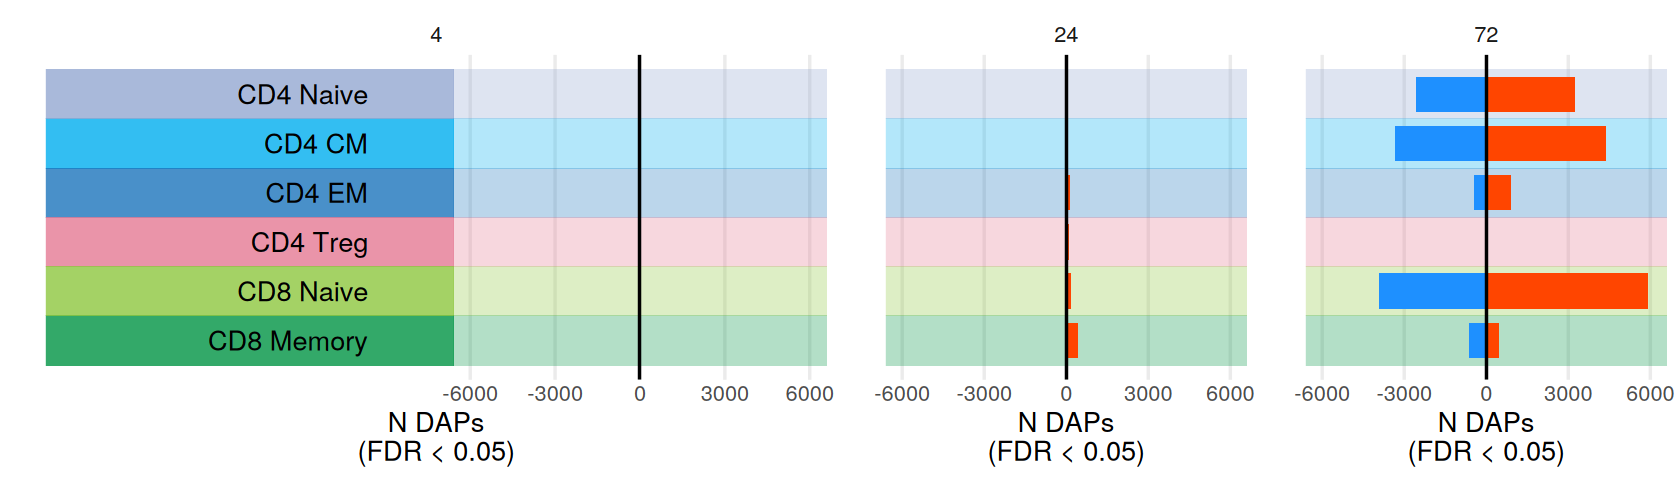

In [40]:
options(repr.plot.width = 14, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 3,
    rel_widths = c(2,1,1)
)
all_plots

In [41]:
out_file <- file.path(
    out_dir,
    paste0("bortezomib_dap_barplot_",Sys.Date(),".pdf")
)
ggsave(out_file,
       all_plots,
       width = 14, height = 4)

### DDE Barplots
Differentially detected epitopes, aka Differentially expressed proteins (DEP)

In [42]:
fdr_cutoff <- 0.05

In [43]:
all_dep <- read.csv(dep_file)

In [44]:
all_dep <- all_dep %>%
  filter(fg == "bortezomib") %>%
  mutate(direction = ifelse(logFC > 0, "up", "dn"))

In [45]:
dep_epitope_summary <- all_dep %>%
  filter(adjP < fdr_cutoff) %>%
  group_by(fg, feature, direction) %>%
  summarise(n_types_up = n(), .groups = "keep")

In [46]:
dep_summary <- all_dep %>%
  group_by(fg, timepoint, aifi_cell_type) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [47]:
plot_data <- dep_summary %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [48]:
plot_data %>%
  filter(fg == "bortezomib",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<int>,<chr>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
bortezomib,4,t_cd4_naive,4,2,2,CD4 Naive,#93A7D1,1,7,bortezomib_4,12
bortezomib,24,t_cd4_naive,3,1,2,CD4 Naive,#93A7D1,1,7,bortezomib_24,12
bortezomib,72,t_cd4_naive,19,12,7,CD4 Naive,#93A7D1,1,7,bortezomib_72,12


In [49]:
write.csv(
    plot_data,
    file.path(out_dir, paste0("bortezomib_dde_summary_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [50]:
treat_times <- paste0("bortezomib_", c(4, 24, 72))

In [51]:
options(repr.plot.width = 12, repr.plot.height = 4)
treat_plots <- map(
    treat_times,
    function(tt) {
        
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        
        timepoint <- pd$timepoint[1]
        
        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DDEs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

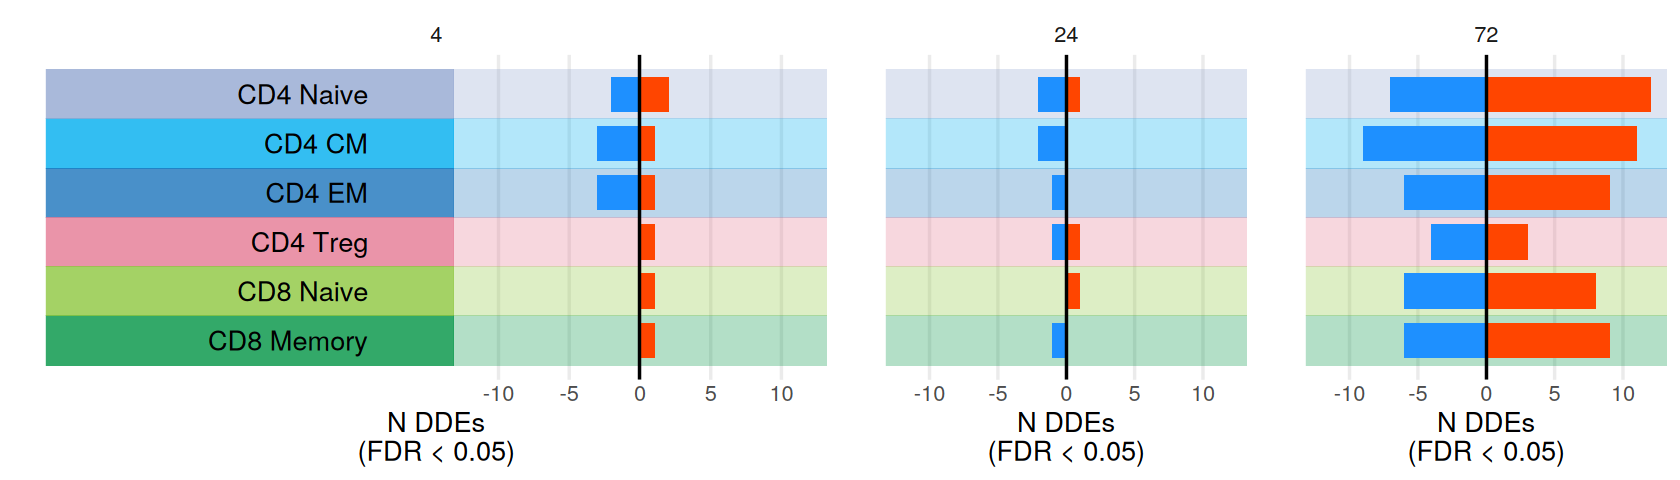

In [52]:
options(repr.plot.width = 14, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 3,
    rel_widths = c(2,1,1)
)
all_plots

In [53]:
out_file <- file.path(
    out_dir,
    paste0("bortezomib_dde_barplot_",Sys.Date(),".pdf")
)
ggsave(out_file,
       all_plots,
       width = 14, height = 4)

## Hallmark pathway enrichment heatmaps

In [54]:
fdr_cutoff <- 0.05

In [55]:
hallmark_names <- read.csv("../common/gene_sets/hallmark_names.csv")

In [56]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv")

Gradient colors

In [57]:
lo_gc <- data.frame(NES = seq(-3, -1.01, 0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkblue", "skyblue"))(n()))
mid_lo_gc <- data.frame(NES = seq(-1, 0, 0.01), nes_color = "gray80")
hi_gc <- data.frame(NES = seq(3,1.01,-0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkred", "coral"))(n()))
mid_hi_gc <- data.frame(NES = seq(1, 0.01, -0.01), nes_color = "gray80")

gc_df <- do.call(rbind, list(lo_gc, mid_lo_gc, mid_hi_gc, hi_gc))
gc_df$NES <- as.character(gc_df$NES)

In [58]:
all_hallmark <- read.csv(hallmark_file)

In [59]:
all_hallmark <- all_hallmark %>%
  filter(fg == "bortezomib")

In [60]:
head(all_hallmark)

,fg,bg,timepoint,aifi_cell_type,pathway_label,NES,nomP,adjP,n_leadingEdge,n_pathway_genes,leadingEdge,pathway_genes
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
1,bortezomib,dmso,24,t_cd4_cm,MYC Targets V1,2.013740,7.204018e-08,3.385888e-06,180,236,PSMD1;PSMD14;PSMB2;PSMD7;PSMA6;PSMC6;RAD23B;PSMD3;PSMB3;PSMA7;HSP90AB1;NAP1L1;PSMC4;SRSF2;PSMA4;PSMA2;CCT3;PTGES3;PSMA1;UBE2L3;PSMD8;XRCC6;CUL1;EIF3J;IFRD1;SRPK1;GLO1,ABCE1;ACP1;AIMP2;AP3S1;APEX1;BUB3;C1QBP;CAD;CANX;CANX;CBX3;CCNA2;CCT2;CCT3;CCT4;CCT5;CCT7;CDC20;CDC45;CDK2;CDK4;CLNS1A;CNBP;COPS5;COX5A;CSTF2;CTPS1;CUL1;CYC1;DDX18;DDX21;DEK;DHX15;DUT;EEF1B2;EEF1B2;EIF1AX;EIF2S1;EIF2S2;EIF3B;EIF3D;EIF3J;EIF4A1;EIF4E;EIF4G2;EIF4H;EIF4H;EPRS1;ERH;ETF1;EXOSC7;FAM120A;FBL;FBL;G3BP1;GLO1;GNL3;GOT2;GSPT1;H2AZ1;HDAC2;HDDC2;HDGF;HNRNPA1;HNRNPA2B1;HNRNPA3;HNRNPC;HNRNPD;HNRNPR;HNRNPR;HNRNPU;HPRT1;HSP90AB1;HSPD1;HSPE1;IARS1;IFRD1;ILF2;IMPDH2;KARS1;KPNA2;KPNB1;LDHA;LDHA;LSM2;LSM2;LSM2;LSM2;LSM2;LSM2;LSM7;MAD2L1;MCM2;MCM4;MCM5;MCM6;MCM7;MRPL23;MRPL23;MRPL9;MRPS18B;MRPS18B;MRPS18B;MRPS18B;MRPS18B;MRPS18B;MRPS18B;MYC;NAP1L1;NCBP1;NCBP2;NDUFAB1;NHP2;NME1;NOLC1;NOP16;NOP56;NPM1;ODC1;ORC2;PA2G4;PABPC1;PABPC4;PCBP1;PCNA;PGK1;PHB;PHB2;POLD2;POLE3;PPIA;PPM1G;PRDX3;PRDX4;PRPF31;PRPF31;PRPF31;PRPF31;PRPF31;PRPF31;PRPF31;PRPF31;PRPF31;PRPF31;PRPS2;PSMA1;PSMA2;PSMA4;PSMA6;PSMA7;PSMB2;PSMB3;PSMB3;PSMC4;PSMC4;PSMC6;PSMD1;PSMD14;PSMD3;PSMD7;PSMD8;PTGES3;PWP1;RACK1;RAD23B;RAN;RANBP1;RFC4;RNPS1;RNPS1;RNPS1;RNPS1;RNPS1;RNPS1;RPL14;RPL18;RPL22;RPL34;RPL6;RPLP0;RPS10;RPS2;RPS3;RPS5;RPS6;RRM1;RRP9;RSL1D1;RUVBL2;SERBP1;SET;SF3A1;SF3B3;SLC25A3;SMARCC1;SNRPA;SNRPA1;SNRPB2;SNRPD1;SNRPD2;SNRPD3;SNRPG;SRM;SRPK1;SRSF1;SRSF2;SRSF3;SRSF7;SSB;SSBP1;SSBP1;STARD7;SYNCRIP;TARDBP;TCP1;TFDP1;TOMM70;TRA2B;TRIM28;TUFM;TXNL4A;TYMS;U2AF1;UBA2;UBE2E1;UBE2L3;USP1;VBP1;VDAC1;VDAC3;XPO1;XPOT;XRCC6;YWHAE;YWHAE;YWHAQ
2,bortezomib,dmso,24,t_cd4_cm,MTORC1 Signaling,1.817862,2.233468e-04,3.499100e-03,142,211,PSMD14;TXNRD1;PSMD12;PSMC6;SQSTM1;PSMC2;PSMA3;NMT1;TBK1;GSR;PSMD13;PRDX1;HSPA9;PSMC4;PSMA4;PSMB5;NUP205;GPI;GBE1;GLA;STIP1;GAPDH;GCLC;IFRD1;ATP2A2;SLC2A3;GLRX;HMGCS1;NIBAN1;GSK3B;HSPD1,ABCF2;ACACA;ACACA;ACLY;ACSL3;ACTR2;ACTR3;ADD3;ADIPOR2;ADIPOR2;AK4;ALDOA;ARPC5L;ASNS;ATP2A2;ATP5MC1;ATP6V1D;AURKA;BCAT1;BHLHE40;BTG2;BUB1;CACYBP;CALR;CANX;CANX;CCNF;CCNG1;CCT6A;CD9;CDC25A;CDKN1A;CFP;COPS5;CORO1A;CTH;CTSC;CXCR4;CYB5B;CYP51A1;DAPP1;DDIT3;DDIT4;DDX39A;DHCR24;DHCR7;DHFR;EBP;EDEM1;EEF1E1;EGLN3;EIF2S2;ELOVL5;ELOVL6;ENO1;EPRS1;ERO1A;ETF1;FADS1;FADS2;FDXR;FGL2;FKBP2;G6PD;GAPDH;GBE1;GCLC;GGA2;GLA;GLRX;GMPS;GOT1;GPI;GPI;GSK3B;GSR;GTF2H1;GTF2H1;HK2;HMBS;HMGCR;HMGCS1;HPRT1;HSP90B1;HSPA4;HSPA5;HSPA9;HSPD1;HSPE1;IDH1;IDI1;IFI30;IFRD1;IGFBP5;IMMT;INSIG1;ITGB2;LDHA;LDHA;LDLR;LGMN;LTA4H;M6PR;MAP2K3;MCM2;MCM4;ME1;MLLT11;MTHFD2;MTHFD2L;NAMPT;NFIL3;NFKBIB;NFKBIB;NFYC;NIBAN1;NMT1;NUFIP1;NUP205;NUPR1;P4HA1;PDAP1;PDK1;PFKL;PGK1;PGM1;PHGDH;PIK3R3;PITPNB;PLK1;PLOD2;PNO1;PNP;POLR3G;PPA1;PPIA;PPP1R15A;PRDX1;PSAT1;PSMA3;PSMA4;PSMB5;PSMC2;PSMC4;PSMC4;PSMC6;PSMD12;PSMD13;PSMD14;PSME3;PSMG1;PSPH;QDPR;RAB1A;RDH11;RIT1;RPA1;RPN1;RRM2;RRP9;SC5D;SCD;SDF2L1;SEC11A;SERP1;SERPINH1;SHMT2;SKAP2;SLA;SLC1A4;SLC1A5;SLC2A1;SLC2A3;SLC37A4;SLC37A4;SLC37A4;SLC6A6;SLC7A11;SLC7A5;SLC9A3R1;SORD;SQLE;SQSTM1;SQSTM1;SRD5A1;SSR1;STARD4;STC1;STIP1;SYTL2;TBK1;TCEA1;TES;TFRC;TM7SF2;TMEM97;TOMM40;TPI1;TRIB3;TUBA4A;TUBG1;TXNRD1;UBE2D3;UCHL5;UFM1;UNG;USO1;VLDLR;WARS1;XBP1;YKT6
3,bortezomib,dmso,24,t_cd4_cm,ROS Pathway,1.755945,9.261899e-03,5.441366e-02,38,58,TXNRD1;TXN;GSR;FTL;PRDX1;GCLM;SOD1;GCLC;PFKP;LAMTOR5;GLRX,ABCC1;ABCC1;ATOX1;CAT;CDKN2D;EGLN2;ERCC2;FES;FTL;G6PD;GCLC;GCLM;GLRX;GLRX2;GPX3;GPX4;GSR;HHEX;HMOX2;HMOX2;IPCEF1;JUNB;LAMTOR5;LSP1;LSP1;MBP;MGST1;MPO;MSRA;MSRA;NDUFA6;NDUFA6;NDUFA6;NDUFA6;NDUFA6;NDUFB4;NDUFS2;NQO1;OXSR1;PDLIM1;PFKP;PRDX1;PRDX2;PRDX4;PRDX6;PRNP;PTPA;SBNO2;SBNO2;SCAF4;SELENOS;SOD1;SOD2;SRXN1;STK25;TXN;TXNRD1;TXNRD2
4,bortezomib,dmso,24,t_cd4_cm,Adipogenesis,1.678625,3.414757e-03,2.621228e-02,121,210,UBC;UBQLN1;TALDO1;NMT1;BAZ2A;SOD1;ACO2;RTN3;GBE1;MAP

Add treat_time, display labels for pathways, and cell type 

In [61]:
plot_hallmark <- all_hallmark %>%
  mutate(label_time = ifelse(timepoint == 4, "04", as.character(timepoint))) %>%
  mutate(treat_time = paste0(fg, "_", label_time)) %>%
  left_join(hallmark_names) %>%
  left_join(type_colors)

Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(aifi_cell_type)`


In [62]:
top_n <- 20

sig_data <- plot_hallmark %>%
  filter(adjP < fdr_cutoff) %>%
  group_by(pathway) %>%
  arrange(adjP) %>%
  slice(1) %>%
  ungroup() %>%
  arrange(adjP) %>%
  head(top_n)

plot_data <- plot_hallmark %>%
  filter(pathway %in% sig_data$pathway)

xpos_df <- plot_data %>%
  select(cell_type_label, cell_type_xpos) %>%
  unique() %>%
  arrange(cell_type_xpos) %>%
  mutate(xpos = 1:n())

ypos_df <- plot_data %>%
  select(pathway_label) %>%
  unique() %>%
  arrange(pathway_label) %>%
  mutate(ypos = n():1)

timepoint_df <- data.frame(
    timepoint = c(4, 24, 72),
    timepoint_label = factor(c("Bortezomib, 4 Hours", "Bortezomib, 24 Hours", "Bortezomib, 72 Hours"), 
                             levels = c("Bortezomib, 4 Hours", "Bortezomib, 24 Hours", "Bortezomib, 72 Hours"))
)

plot_data <- plot_data %>%
  left_join(xpos_df) %>%
  left_join(ypos_df) %>%
  mutate(NES = as.character(round(NES, 2))) %>%
  left_join(gc_df) %>%
  left_join(timepoint_df)

Joining with `by = join_by(cell_type_label, cell_type_xpos)`
Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(NES)`
Joining with `by = join_by(timepoint)`


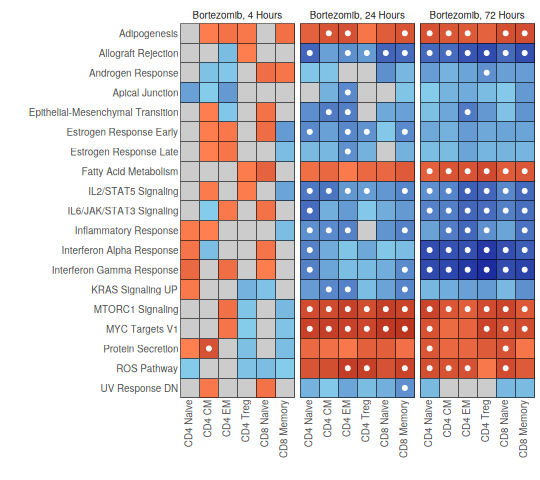

In [63]:
options(repr.plot.width = 4.5, repr.plot.height = 4)
hallmark_plot <- ggplot() +
  geom_tile(
      data = plot_data,
      aes(x = xpos,
          y = ypos,
          fill = nes_color),
      color = "black") +
  geom_point(
      data = plot_data %>% filter(adjP < fdr_cutoff),
      aes(x = xpos,
          y = ypos),
      color = "white",
      size = 0.9) +
  scale_fill_identity() +
  scale_x_continuous(
      "",
      breaks = xpos_df$xpos,
      labels = xpos_df$cell_type_label,
      expand = c(0, 0)) +
  scale_y_continuous(
      "",
      breaks = ypos_df$ypos,
      labels = ypos_df$pathway_label,
      expand = c(0, 0)) +
  facet_wrap(~ timepoint_label) +
  theme_bw(base_size = 7) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.border = element_blank(),
        axis.ticks = element_blank(),
        strip.background = element_blank(),
        panel.grid = element_blank(),
        panel.background = element_rect(fill = "gray30"))
hallmark_plot

In [64]:
out_file <- file.path(
    out_dir,
    paste0("bortezomib_hallmark_heatmap_",Sys.Date(),".pdf")
)
ggsave(out_file,
       hallmark_plot,
       width = 4.5, height = 4)

## Motif enrichment volcano plots

Select columns from DEG results to highlight TFs that are differentially expressed by color in the volcano plots

In [65]:
sel_deg <- all_deg %>%
  select(aifi_cell_type, timepoint, fg, bg, gene, adjP, logFC, direction) %>%
  rename(tf_gene = gene,
         tf_adjP = adjP,
         tf_logFC = logFC,
         tf_direction = direction) 

Read the motif enrichment results

In [66]:
all_dem <- read.csv(dem_file)

In [67]:
all_dem <- all_dem %>%
  mutate(timepoint = as.numeric(sub(".+_","",fg)),
         fg = sub("_.+","",fg),
         bg = sub("_.+","",bg)) %>%
  filter(fg == "bortezomib") %>%
  left_join(sel_deg)

Joining with `by = join_by(aifi_cell_type, fg, bg, tf_gene, timepoint)`


Filter for expressed TFs, which will have tf_adjP, tf_logFC, and tf_direction joined from the DEG results

In [68]:
all_dem <- all_dem %>%
  filter(!is.na(tf_direction))

Convert Enrichment for motifs enriched near down-regulated genes to negative values

In [69]:
all_dem <- all_dem %>%
  mutate(Enrichment = ifelse(
      direction == "dn",
      -1 * Enrichment,
      Enrichment))

Add cell type labels and ordering

In [70]:
head(type_colors)

,aifi_cell_type,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos
,<chr>,<chr>,<chr>,<int>,<int>
1,t_cd4_naive,CD4 Naive,#93A7D1,1,7
2,t_cd4_cm,CD4 CM,#00AEEF,2,6
3,t_cd4_em,CD4 EM,#1C75BC,3,5
4,t_cd4_treg,CD4 Treg,#E57A93,4,4
5,t_cd8_naive,CD8 Naive,#8DC63F,5,3
6,t_cd8_memory,CD8 Memory,#009444,6,2


In [71]:
all_dem <- all_dem %>%
  left_join(type_colors) %>%
  mutate(cell_type_label = factor(cell_type_label, levels = type_colors$cell_type_label))

Joining with `by = join_by(aifi_cell_type)`


In [72]:
plot_dem <- all_dem %>%
  filter(timepoint == 72) %>%
  mutate(color = case_when(
      tf_adjP < 0.05 & tf_direction == "up" ~ "orangered",
      tf_adjP < 0.05 & tf_direction == "dn" ~ "dodgerblue",
      TRUE ~ "gray60",
  ))

In [73]:
write.csv(
    plot_dem,
    file.path(out_dir, paste0("bortezomib_72hr_dem_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [74]:
max_enrich <- max(plot_dem$Enrichment)
max_mlp <- max(plot_dem$mlog10Padj)

In [75]:
label_top_n <- 8

up_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "up") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  slice(1:label_top_n) %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = label_top_n),
         xpos = max_enrich * 1.1) %>%
  ungroup() 

dn_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "dn") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  slice(1:label_top_n) %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = label_top_n),
         xpos = -1 * max_enrich * 1.1) %>%
  ungroup()

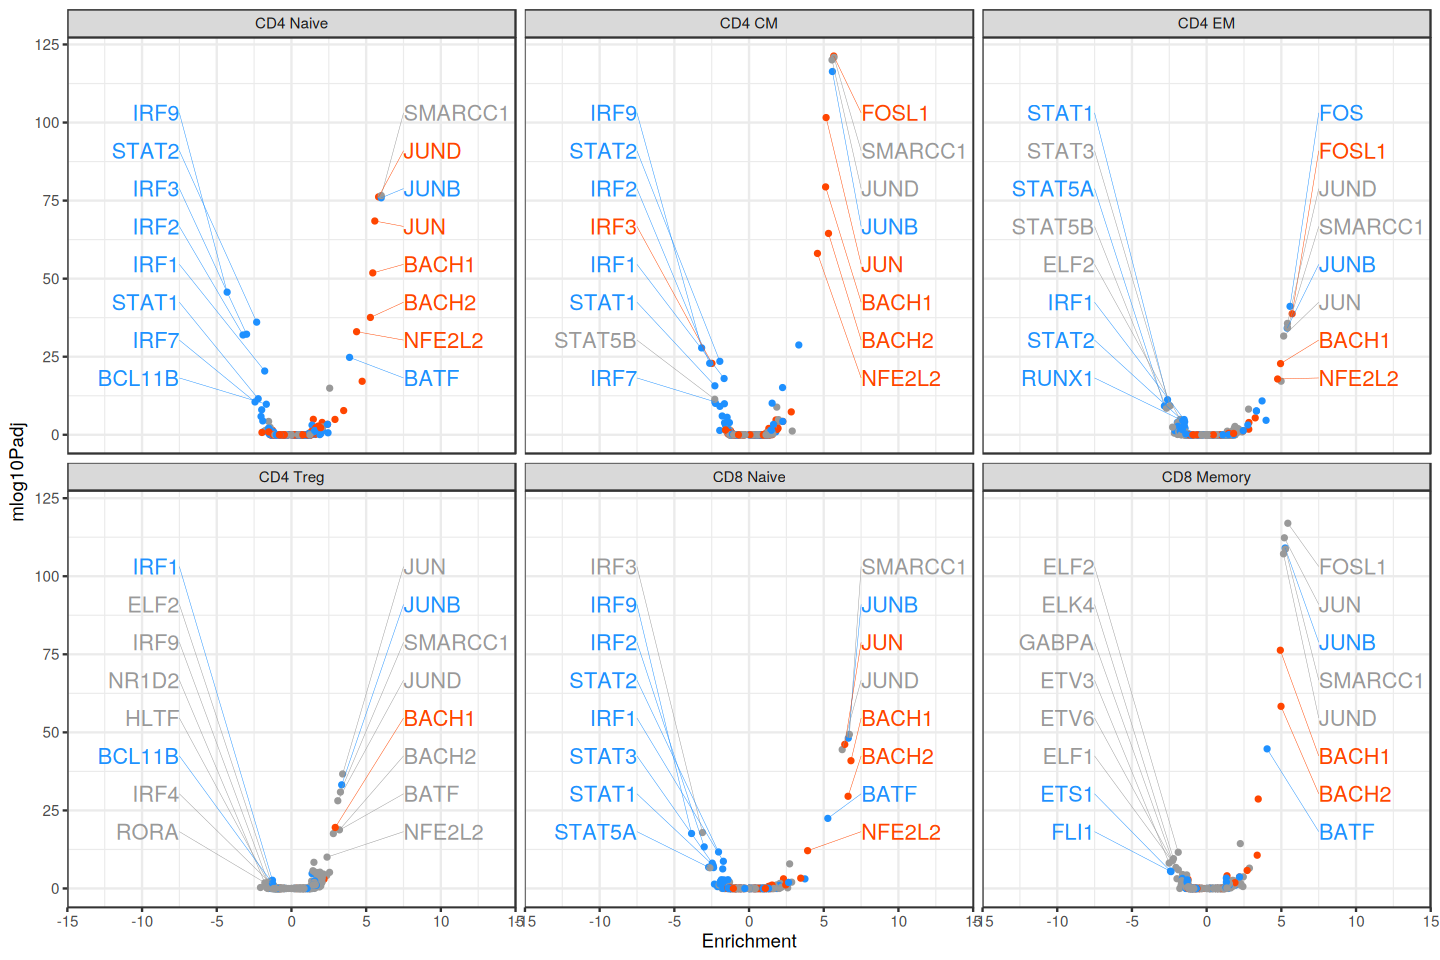

In [76]:
options(repr.plot.width = 12, repr.plot.height = 8)

volcano_plots <- ggplot() +
  geom_point(
      data = plot_dem,
      aes(x = Enrichment,
          y = mlog10Padj,
          color = color),
      size = 1
  ) +
  geom_segment(
      data = up_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = up_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 0
  ) +
  geom_segment(
      data = dn_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = dn_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 1
  ) +
  scale_color_identity() +
  scale_x_continuous(
      limits = c(-2 * max_enrich, 2 * max_enrich)
  ) +
  facet_wrap(
      ~ cell_type_label,
      ncol = 3,
      nrow = 2
  ) +
  theme_bw()

volcano_plots

In [77]:
out_file <- file.path(
    out_dir,
    paste0("bortezomib_72hr_dem_volcano_plots_",Sys.Date(),".pdf")
)
ggsave(out_file,
       volcano_plots,
       width = 12, height = 8)

# Store results in HISE

Finally, we store the output file in our Collaboration Space for later retrieval and use. We need to provide the UUID for our Collaboration Space (aka `studySpaceId`), as well as a title for this step in our analysis process.

The hise function `uploadFiles()` also requires the FileIDs from the original fileset for reference.

In [78]:
study_space_uuid <- "40df6403-29f0-4b45-ab7d-f46d420c422e"
title <- paste("VRd TEA-seq Fig 3", Sys.Date())

In [79]:
out_files <- list.files(
    out_dir,
    full.names = TRUE
)
out_list <- as.list(out_files)

In [80]:
out_list

[[1]]
[1] "output/figure_3/bortezomib_72hr_dem_data_2026-11-06.csv"

[[2]]
[1] "output/figure_3/bortezomib_72hr_dem_volcano_plots_2026-11-06.pdf"

[[3]]
[1] "output/figure_3/bortezomib_dap_barplot_2026-11-06.pdf"

[[4]]
[1] "output/figure_3/bortezomib_dap_summary_data_2026-11-06.csv"

[[5]]
[1] "output/figure_3/bortezomib_dde_barplot_2026-11-06.pdf"

[[6]]
[1] "output/figure_3/bortezomib_dde_summary_data_2026-11-06.csv"

[[7]]
[1] "output/figure_3/bortezomib_deg_barplot_2026-11-06.pdf"

[[8]]
[1] "output/figure_3/bortezomib_deg_summary_data_2026-11-06.csv"

[[9]]
[1] "output/figure_3/bortezomib_hallmark_heatmap_2026-11-06.pdf"

In [81]:
in_list <- c(deg_uuid, dep_uuid, dap_uuid, hallmark_uuid, dem_uuid)

In [82]:
sessionInfo()

R version 4.4.1 (2024-06-14)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/workspace/environment/archrpixiv12/.pixi/envs/default/lib/libopenblasp-r0.3.33.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8    LC_NUMERIC=C        LC_TIME=C          
 [4] LC_COLLATE=C        LC_MONETARY=C       LC_MESSAGES=C      
 [7] LC_PAPER=C          LC_NAME=C           LC_ADDRESS=C       
[10] LC_TELEPHONE=C      LC_MEASUREMENT=C    LC_IDENTIFICATION=C

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] cowplot_1.2.0 ggrepel_0.9.8 ggplot2_4.0.3 dplyr_1.2.1   purrr_1.2.2  
[6] hise_3.6.15  

loaded via a namespace (and not attached):
 [1] gtable_0.3.6       jsonlite_2.0.0     compiler_4.4.1     crayon_1.5.3      
 [5] tidyselect_1.2.1   Rcpp_1.1.1-1.1     IRdisplay_1.1      bitops_1.0-9      

In [87]:
uploadFiles(
    files = out_list,
    studySpaceId = study_space_uuid,
    title = title,
    inputFileIds = in_list,
    store = "project",
    doPrompt = FALSE
)

[1] "Cannot determine the current notebook."
[1] "1) /home/jupyter/repro-vrd-tea-seq/figures/Fig-2_bor_overview.ipynb"
[1] "2) /home/jupyter/repro-vrd-tea-seq/figures/Fig-4_len_overview.ipynb"
[1] "3) /home/jupyter/repro-vrd-tea-seq/figures/Fig-6_dex_overview.ipynb"


Please select (1-3)  1


$files
$files[[1]]
[1] "output/figure_2/bortezomib_72hr_dem_data_2023-10-18.csv"

$files[[2]]
[1] "output/figure_2/bortezomib_72hr_dem_volcano_plots_2023-10-18.pdf"

$files[[3]]
[1] "output/figure_2/bortezomib_dap_barplot_2023-10-18.pdf"

$files[[4]]
[1] "output/figure_2/bortezomib_dap_summary_data_2023-10-18.csv"

$files[[5]]
[1] "output/figure_2/bortezomib_dde_barplot_2023-10-18.pdf"

$files[[6]]
[1] "output/figure_2/bortezomib_dde_summary_data_2023-10-18.csv"

$files[[7]]
[1] "output/figure_2/bortezomib_deg_barplot_2023-10-18.pdf"

$files[[8]]
[1] "output/figure_2/bortezomib_deg_summary_data_2023-10-18.csv"

$files[[9]]
[1] "output/figure_2/bortezomib_hallmark_heatmap_2023-10-18.pdf"


$traceId
[1] "59d9007a-753b-4d7c-9a8a-2a0d4c56b80a"